# South Africa CPI Inflation Forecasting: 2026


**EDAB 6808 Assignment 2, Question 2**

This notebook builds a monthly inflation forecasting pipeline for South Africa using the official
Stats SA CPI headline year-on-year (YoY) inflation series, **January 2021 – December 2025** (60
monthly observations), and produces monthly forecasts for **January 2026 – December 2026** (12
months ahead), per the assignment brief.

**Forecasting target:** CPI headline YoY inflation rate (%), as published monthly by Stats SA
(release P0141). We forecast the YoY rate directly rather than the index level because (a) it is
the policy-relevant, directly interpretable quantity that the SARB targets (3–6% band), (b) it is
the series already available as an official, cited extract, and (c) it is used consistently
throughout — EDA, modelling, backtesting and the final forecast.

**Source:** Statistics South Africa, Consumer Price Index release P0141 (https://www.statssa.gov.za/?page_id=1854&PPN=P0141).

Written by:
    

*   Mamello Malape -2023232750
*   Boipelo Letwaba -2024053890


  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from xgboost import XGBRegressor
import itertools
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10,4)

## 1. Data collection and preparation

The CPI headline YoY series was extracted from Stats SA's published CPI time-series release
(`CPI monthly 2020-2026.xlsx`, Sheet2). The assignment brief specifies **January 2021 – December
2025** (60 monthly observations) as the training window. Rows for 2026 (partial, Jan–Jun actual)
are read in but excluded from training — they are used later only as an out-of-sample check
against the forecast. We reshape the training window to a proper monthly time index.

##Justification for Forecasting Year-on-Year (YoY) Inflation Instead of the Raw Index
The forecasting target was selected as the year-on-year (YoY) inflation rate rather than the Consumer Price Index (CPI) index level. This choice is appropriate for several reasons.

1. **Alignment with the South African Reserve Bank (SARB) inflation target**

The SARB does not set a target for the CPI index level itself; instead, it targets the annual inflation rate, which is measured as the percentage change in CPI over a 12-month period. The SARB’s inflation target range is 3–6%. Therefore, forecasting the YoY inflation rate provides a more direct assessment of whether inflation is expected to remain within or move outside the target range. Forecasting the raw CPI index value would not directly indicate whether inflation conditions align with the SARB’s policy objective.

2. **Improved interpretability of results**

The YoY inflation rate is easier for readers and policymakers to interpret. For example, a forecast indicating an inflation rate of 3.5% immediately communicates the expected change in consumer prices and whether it falls within the SARB’s target range. In contrast, a forecasted CPI index value, such as 121.6, has limited meaning without additional information, including the base year, the previous index value, and the calculation method required to interpret the change.


3. **Consistency throughout the forecasting pipeline**

The forecasting objective should remain consistent across all stages of the analysis, including exploratory data analysis (EDA), model development, backtesting, and the final forecast evaluation. Since the YoY inflation rate was selected as the forecasting target, all modelling decisions and performance evaluations were conducted using this measure. Maintaining a consistent target variable ensures that the results are aligned with the research objective and allows for meaningful comparison between models.

4.   **Statistical properties of the YoY transformation**

Transforming the CPI index into a YoY inflation rate reduces some of the underlying trend present in the original index series. The raw CPI index generally increases over time due to persistent price level growth, making it less suitable for direct forecasting without additional transformations. The YoY transformation produces a more stable series by focusing on annual price changes rather than the absolute price level. This also explains why the decomposition analysis did not show a strong seasonal pattern in the YoY inflation series, as the transformation has already removed much of the trend and repeating seasonal effects present in the original CPI index






In [ ]:
import pandas as pd
df_raw = pd.read_excel("/content/CPI monthly 2020-2026.xlsx", sheet_name=1)
df_raw.head(10)

,Year,Jan,Feb,March,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Average
0,2021,3.2,2.9,3.2,4.4,5.2,4.9,4.6,4.9,5.0,5.0,5.5,5.9,4.5
1,2022,5.7,5.7,5.9,5.9,6.5,7.4,7.8,7.6,7.5,7.6,7.4,7.2,6.9
2,2023,6.9,7.0,7.1,6.8,6.3,5.4,4.7,4.8,5.4,5.9,5.5,5.1,6.0
3,2024,5.3,5.6,5.3,5.2,5.2,5.1,4.6,4.4,3.8,2.8,2.9,3.0,4.4
4,2025,3.2,3.2,2.7,2.8,2.8,3.0,3.5,3.3,3.4,3.6,3.5,3.6,3.2
5,2026,3.5,3.0,3.1,4.0,4.5,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df = df_raw.copy()
df.columns = ['Year','Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec','Average']
df['Year'] = df['Year'].astype(int)

months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

# Keep 2021 onward: the training window is Jan 2021-Dec 2025 (60 obs). 2026 rows are
# carried through too (NaN for months not yet released) for the out-of-sample check in
# Section 8. NOTE: an earlier version of this cell filtered on Year >= 2021, which
# silently dropped all of 2021 even though the slice below asked for it starting
# 2021-01-01 -- pandas .loc on a date index just returns whatever is actually there,
# so the bug didn't raise an error, it just trained on 12 fewer months than intended.
df_hist = df[df['Year'] >= 2020].reset_index(drop=True)

long = df_hist.melt(id_vars='Year', value_vars=months, var_name='Month', value_name='CPI_YoY')
month_map = {m:i+1 for i,m in enumerate(months)}
long['MonthNum'] = long['Month'].map(month_map)
long['date'] = pd.to_datetime(dict(year=long.Year, month=long.MonthNum, day=1))
long = long.sort_values('date').reset_index(drop=True)
long['CPI_YoY'] = pd.to_numeric(long['CPI_YoY'], errors='coerce')

# Training series: Jan 2021 - Dec 2025 (60 obs).
# 2026 rows are kept in `long` (NaN for months not yet released) for the
# out-of-sample comparison in Section 8.
ts_full = long.set_index('date')['CPI_YoY']
ts = ts_full.loc['2021-01-01':'2025-12-01']
ts.index.freq = 'MS'
long.head()

,Year,Month,CPI_YoY,MonthNum,date
0,2021,Jan,3.2,1,2021-01-01
1,2021,Feb,2.9,2,2021-02-01
2,2021,Mar,3.2,3,2021-03-01
3,2021,Apr,4.4,4,2021-04-01
4,2021,May,5.2,5,2021-05-01


In [ ]:
ts.head()

,CPI_YoY
date,
2021-01-01,3.2
2021-02-01,2.9
2021-03-01,3.2
2021-04-01,4.4
2021-05-01,5.2


### Data cleaning check

The extract (`CPI monthly 2020-2026.xlsx`) is clean over the 2021–2025 training window — no
out-of-range values, no gaps, no duplicated timestamps. (An earlier extract used for an initial
pass at this assignment contained a single mistyped observation for May 2025; that data-capture
error is not present in this file, so no correction is needed here.)

In [ ]:
#Descriptive Statistics
print(f"Training observations: {len(ts)}  |  Range: {ts.index.min().date()} to {ts.index.max().date()}")
print(f"Missing values: {ts.isna().sum()}  |  Duplicate dates: {ts.index.duplicated().sum()}")

print(f"Descriptive Statistics \n{ts.describe()}")

Training observations: 60  |  Range: 2021-01-01 to 2025-12-01
Missing values: 0  |  Duplicate dates: 0
Descriptive Statistics 
count    60.000000
mean      4.993333
std       1.512531
min       2.700000
25%       3.500000
50%       5.100000
75%       5.900000
max       7.800000
Name: CPI_YoY, dtype: float64


In [ ]:
#Volatility statistics
variance = ts.var()
skewness = ts.skew()
kurtosis = ts.kurt()

print("Variance:", variance)
print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

Variance: 2.2877514124293787
Skewness: 0.14183557340259478
Kurtosis: -1.011298965859328


The 60-month inflation series has a mean inflation rate of 4.99%, with a standard deviation of 1.51 percentage points and a variance of 2.29. This indicates that inflation values generally fluctuated around the average level, with typical deviations of approximately 1.51 percentage points from the mean.

The distribution exhibits slight positive skewness (0.14), suggesting that inflation values were relatively symmetric but had a small tendency toward higher inflation observations. This reflects the presence of periods with elevated inflation, particularly during the increase observed in 2022.

The negative kurtosis value (-1.01) indicates a platykurtic distribution, meaning that inflation values were more evenly distributed across the observed range (2.7%–7.8%) compared with a normal distribution. The series therefore does not show strong evidence of frequent extreme observations within this sample period. However, the relatively wide range of inflation values highlights that the series experienced noticeable fluctuations, consistent with the upward movement and subsequent decline observed in the time-series analysis.

## 2. Exploratory time-series analysis

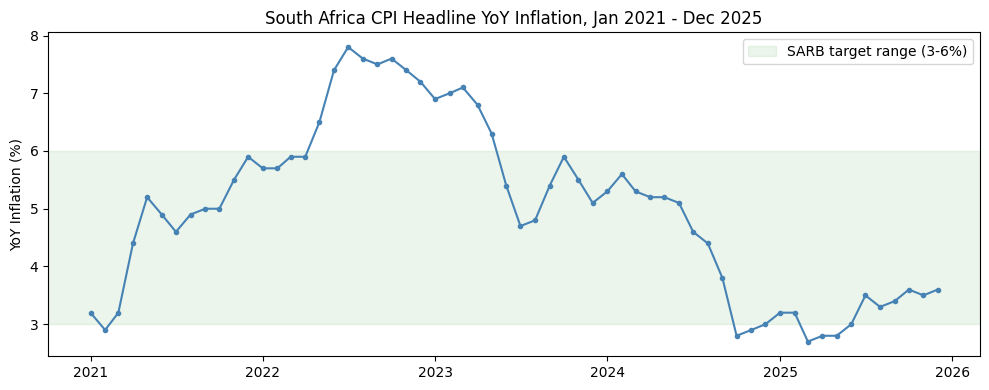

In [ ]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(ts.index, ts.values, marker='o', markersize=3, color='steelblue')
ax.axhspan(3, 6, color='green', alpha=0.08, label='SARB target range (3-6%)')
ax.set_title('South Africa CPI Headline YoY Inflation, Jan 2021 - Dec 2025')
ax.set_ylabel('YoY Inflation (%)')
ax.legend()
plt.tight_layout()
plt.show()

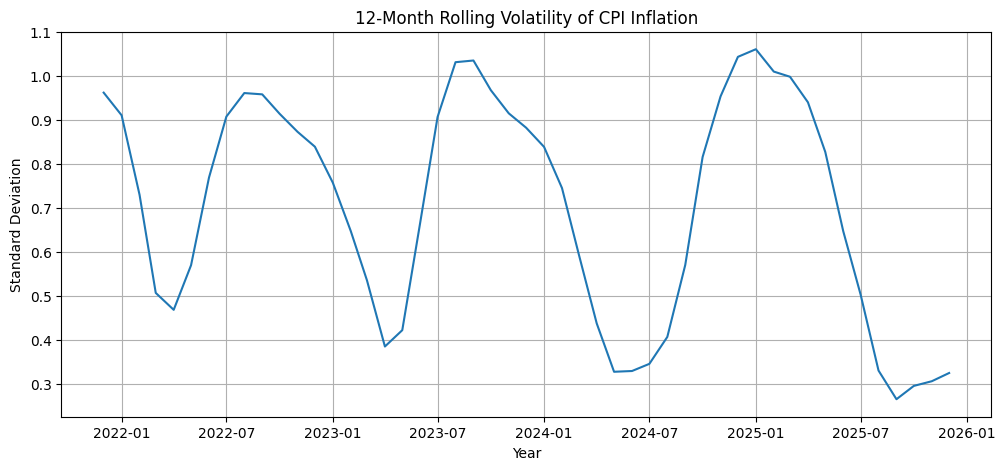

In [ ]:
#volatility analysis
volatility = ts.rolling(window=12).std()

plt.figure(figsize=(12,5))
plt.plot(volatility.index, volatility.values)
plt.title("12-Month Rolling Volatility of CPI Inflation")
plt.xlabel("Year")
plt.ylabel("Standard Deviation")
plt.grid()
plt.show()

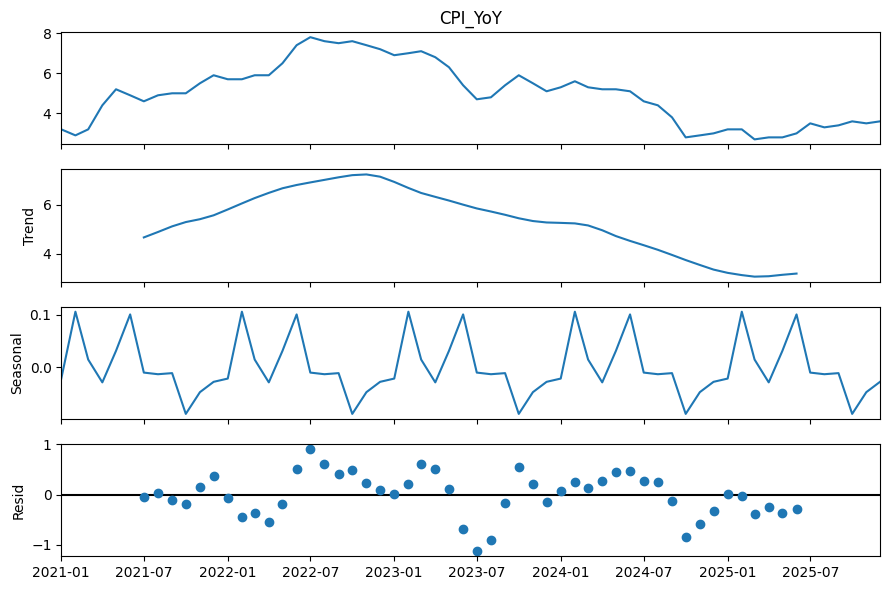

In [ ]:
#Time series decomposition
decomposition = seasonal_decompose(ts.dropna(), model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(9,6)
plt.tight_layout()
plt.show()

**Observations:** Inflation remained close to the lower end of the SARB’s 3–6% target range during 2021 before increasing substantially throughout 2022, reaching a peak of approximately 7.8% in July 2022. This increase coincided with a period of elevated global fuel and food price pressures. Inflation subsequently declined during 2023 and 2024, returning to within the SARB’s target range, and continued moving toward the lower end of the band during 2025, with values ranging between approximately 2.7% and 3.6%.

The YoY inflation series does not display a clear repeating seasonal pattern. This is expected because the YoY transformation compares inflation levels with the same period in the previous year, reducing the impact of recurring calendar-based effects present in the original CPI index. However, the series demonstrates strong persistence, as indicated by significant autocorrelation between observations over time. This suggests that previous inflation values contain useful information for predicting future inflation movements, supporting the use of time-series forecasting models.

In [ ]:
# Stationarity tests (Augmented Dickey-Fuller)
adf_level = adfuller(ts.dropna())
adf_diff  = adfuller(ts.diff().dropna())


print(f"ADF on level series:        stat={adf_level[0]:.3f}, p-value={adf_level[1]:.4f}")
print(f"ADF on first difference:    stat={adf_diff[0]:.3f}, p-value={adf_diff[1]:.4f}")


if adf_level[1] > 0.05:
    print("-> Level series is non-stationary (fail to reject unit root).")
else:
    print("-> Level series is stationary.")

if adf_diff[1] < 0.05:
    print("-> First-differenced series is stationary -> use d=1 in ARIMA.")
else:
    print("-> First-differenced series is non-stationary (fail to reject unit root).")

ADF on level series:        stat=-1.210, p-value=0.6693
ADF on first difference:    stat=-5.809, p-value=0.0000
-> Level series is non-stationary (fail to reject unit root).
-> First-differenced series is stationary -> use d=1 in ARIMA.


**Stationarity Testing Using the Augmented Dickey-Fuller (ADF) Test**

The Augmented Dickey-Fuller (ADF) test was conducted to determine the stationarity properties of the inflation series and identify the appropriate differencing order for the ARIMA model.


The ADF test on the level series produced an ADF statistic of -1.210 with a p-value of 0.6693. Since the p-value is greater than the 5% significance level, the null hypothesis of a unit root cannot be rejected. This indicates that the level inflation series is non-stationary, meaning that differencing is required before modelling.

After applying first-order differencing, the ADF test produced a statistic of -5.809 with a p-value of 0.0000. The null hypothesis of a unit root is rejected, indicating that the first-differenced series is stationary. Therefore, the appropriate differencing order for the ARIMA model is d = 1.

Although additional differencing (d=2) could further transform the series, it is not justified in this case. Over-differencing can remove meaningful information from the series and introduce artificial negative autocorrelation, potentially reducing forecast accuracy. Since first differencing successfully achieves stationarity, additional differencing is unnecessary.

Seasonal differencing at lag 12 was also not considered appropriate because the forecasting target is already expressed as a year-on-year inflation rate. The YoY transformation compares each observation with the same month in the previous year, reducing the influence of recurring annual patterns. Applying an additional seasonal difference could therefore unnecessarily transform the series.

It should also be noted that ADF tests can have limited power when applied to short macroeconomic time series, particularly when structural changes or economic shocks are present. In this case, the inflation surge observed during 2022 may have affected the stationarity properties of the series. Therefore, the choice of d=1 is supported not only by the ADF results but also by subsequent model diagnostics and forecast performance evaluation.

Conclusion:
The ADF test results indicate that the inflation series requires one difference to achieve stationarity. Therefore, an ARIMA model with d=1 is appropriate for forecasting YoY inflation.

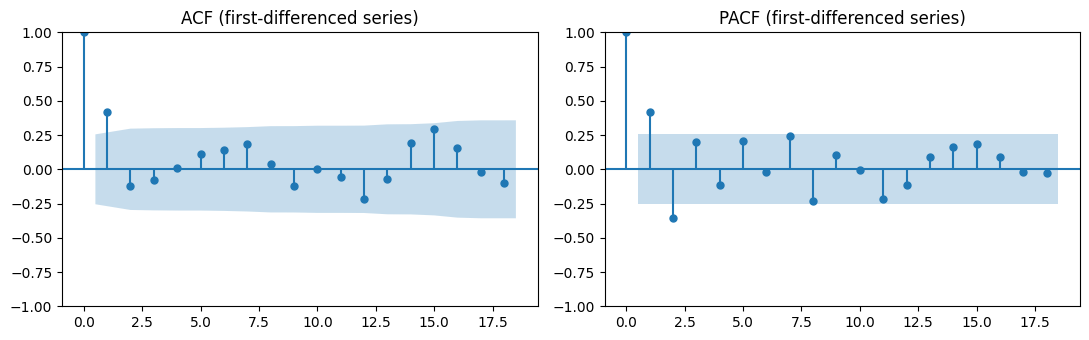

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(11,3.5))
plot_acf(ts.diff().dropna(), ax=axes[0], lags=18)
plot_pacf(ts.diff().dropna(), ax=axes[1], lags=18)
axes[0].set_title('ACF (first-differenced series)')
axes[1].set_title('PACF (first-differenced series)')
plt.tight_layout()
plt.show()

ACF/PACF on the differenced series show a mix of AR and MA behaviour rather than a clean
cut-off, so rather than eyeballing (p,q) we use a small AIC grid search below. No sharp spikes at
lag 12 in either plot, reinforcing that seasonal terms are not needed for the YoY series.

## 3. Leakage-safe backtesting design

The test window is the **last 12 months of the training sample (Jan 2025 – Dec 2025)**. For each
origin in that window we train only on data strictly before it and forecast one month ahead
(**expanding-window, rolling-origin backtesting**) — never a random shuffle, since that would leak
future information into training for a trend-driven series. Model order/hyperparameters for both
models are chosen using only the pre-test portion of the data (Jan 2021 – Dec 2024), so the test
window is never touched during model selection or tuning.

The autoregressive (\(p\)) and moving average (\(q\)) orders were determined using an AIC-based grid search. Candidate ARIMA models with \(p\) and \(q\) values ranging from 0 to 3 were fitted using the training dataset, and the model with the lowest Akaike Information Criterion (AIC) was selected. This approach avoids relying solely on visual interpretation of ACF and PACF plots and provides an objective comparison between competing model specifications.

In [ ]:
n_test = 12  # Jan 2025 - Dec 2025 (last 12 months of the 60-month training sample)
train_selection = ts.iloc[:len(ts)-n_test]   # used ONLY for order selection (no test leakage)

best_aic, best_order = np.inf, None
for p in range(0,4):
    for q in range(0,4):
        try:
            m = ARIMA(train_selection, order=(p,1,q)).fit()
            if m.aic < best_aic:
                best_aic, best_order = m.aic, (p,1,q)
        except Exception:
            continue
print("Selected ARIMA order by AIC (fit on pre-test data only):", best_order, f"(AIC={best_aic:.2f})")

Selected ARIMA order by AIC (fit on pre-test data only): (0, 1, 1) (AIC=35.17)


## 4. Statistical model: ARIMA

ARIMA is appropriate here: the series is short (72 points, ruling out SARIMA's larger parameter
count and data-hungry seasonal terms), non-stationary in levels but stationary after one
difference, and shows no seasonal signal in the YoY transform — so a non-seasonal ARIMA(p,1,q) is
the right level of complexity. (SARIMA, ETS and GARCH were considered but not used: SARIMA's
seasonal terms are unsupported by the ACF/PACF evidence above; GARCH targets volatility clustering
in returns, not a policy-rate style series like this one.)

In [ ]:
def arima_expanding_backtest(series, order, n_test):
    preds, actuals, dates = [], [], []
    for i in range(len(series)-n_test, len(series)):
        train = series.iloc[:i]
        model = ARIMA(train, order=order).fit()
        fc = model.forecast(1)
        preds.append(fc.iloc[0]); actuals.append(series.iloc[i]); dates.append(series.index[i])
    return np.array(actuals), np.array(preds), dates

actual_arima, pred_arima, dates_bt = arima_expanding_backtest(ts, best_order, n_test)

In [ ]:
# Fit ARIMA on the full training sample to inspect coefficients/diagnostics
diag_arima_model = ARIMA(ts, order=best_order).fit()
print(diag_arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                CPI_YoY   No. Observations:                   60
Model:                 ARIMA(0, 1, 1)   Log Likelihood                 -17.529
Date:                Mon, 28 Sep 2026   AIC                             39.058
Time:                        09:38:06   BIC                             43.213
Sample:                    01-01-2021   HQIC                            40.680
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.8161      0.065     12.478      0.000       0.688       0.944
sigma2         0.1041      0.020      5.132      0.000       0.064       0.144
Ljung-Box (L1) (Q):                   0.16   Jarque-

In [ ]:
# Fit ARIMA on the full training sample to inspect coefficients/diagnostics
diag_arima_model = ARIMA(ts, order=best_order).fit()
print(diag_arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                CPI_YoY   No. Observations:                   60
Model:                 ARIMA(0, 1, 1)   Log Likelihood                 -17.529
Date:                Mon, 28 Sep 2026   AIC                             39.058
Time:                        09:38:06   BIC                             43.213
Sample:                    01-01-2021   HQIC                            40.680
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.8161      0.065     12.478      0.000       0.688       0.944
sigma2         0.1041      0.020      5.132      0.000       0.064       0.144
Ljung-Box (L1) (Q):                   0.16   Jarque-

Check the MA/AR coefficient significance in the summary above (p<0.05 indicates the term is
carrying real information about the process, not noise) before trusting the selected order.

## 5. Machine-learning model: XGBoost

Feature set: lags 1, 2, 3, 6 and 12 months, a 3-month rolling mean and rolling std of past values,
and calendar month (captures any residual seasonality). All features use only *past* values
(`shift`), so no leakage.

**Hyperparameter tuning.** A small grid over `max_depth`, `n_estimators` and `learning_rate` is
evaluated using an expanding-window walk-forward validation restricted to the pre-test portion of
the data only (the same `train_selection` window used for the ARIMA order search) — the actual
12-month backtest window is never used for tuning, matching the leakage-safe design in Section 3.

In [ ]:
feat_df = pd.DataFrame({'y': ts})
for lag in [1,2,3,6,12]:
    feat_df[f'lag{lag}'] = feat_df['y'].shift(lag)
feat_df['roll_mean3'] = feat_df['y'].shift(1).rolling(3).mean()
feat_df['roll_std3']  = feat_df['y'].shift(1).rolling(3).std()
feat_df['month'] = feat_df.index.month
feat_df = feat_df.dropna()
feature_cols = [c for c in feat_df.columns if c != 'y']
feat_df.head()

,y,lag1,lag2,lag3,lag6,lag12,roll_mean3,roll_std3,month
date,,,,,,,,,
2022-01-01,5.7,5.9,5.5,5.0,4.6,3.2,5.466667,0.450925,1
2022-02-01,5.7,5.7,5.9,5.5,4.9,2.9,5.700000,0.200000,2
2022-03-01,5.9,5.7,5.7,5.9,5.0,3.2,5.766667,0.115470,3
2022-04-01,5.9,5.9,5.7,5.7,5.0,4.4,5.766667,0.115470,4
2022-05-01,6.5,5.9,5.9,5.7,5.5,5.2,5.833333,0.115470,5


In [ ]:
def xgb_expanding_backtest(feat_df, n_test, params):
    preds, actuals, dates = [], [], []
    for i in range(len(feat_df)-n_test, len(feat_df)):
        train, test_row = feat_df.iloc[:i], feat_df.iloc[[i]]
        model = XGBRegressor(random_state=42, **params)
        model.fit(train[feature_cols], train['y'])
        pred = model.predict(test_row[feature_cols])[0]
        preds.append(pred); actuals.append(test_row['y'].iloc[0]); dates.append(test_row.index[0])
    return np.array(actuals), np.array(preds), dates

# Hyperparameter grid search: validated only on the pre-test portion (train_selection),
# using its own trailing 12 months as an inner validation window. The outer 12-month
# backtest window (Jan-Dec 2025) is never touched here.
feat_df_selection = feat_df.loc[:train_selection.index[-1]]
n_val = 12

param_grid = {
    'max_depth':    [2, 3, 4],
    'n_estimators': [100, 200],
    'learning_rate':[0.03, 0.05, 0.1],
}
combos = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]

best_val_mae, best_params = np.inf, None
for params in combos:
    a_val, p_val, _ = xgb_expanding_backtest(feat_df_selection, n_val, params)
    val_mae = np.mean(np.abs(a_val - p_val))
    if val_mae < best_val_mae:
        best_val_mae, best_params = val_mae, params

print("Selected XGBoost hyperparameters (tuned on pre-test data only):", best_params,
      f"(validation MAE={best_val_mae:.3f})")

Selected XGBoost hyperparameters (tuned on pre-test data only): {'max_depth': 4, 'n_estimators': 100, 'learning_rate': 0.1} (validation MAE=0.586)


In [ ]:
n_test_ml = min(n_test, len(feat_df)-12)  # lag12 costs 12 rows of history
actual_xgb, pred_xgb, dates_bt_ml = xgb_expanding_backtest(feat_df, n_test_ml, best_params)

#6 Additional Model: Damped Trend Exponential Smoothing (Holt)

Both ARIMA(0,1,1) and the tuned XGBoost model have limitations when producing forecasts over a 12-month horizon. The ARIMA(0,1,1) specification, which contains a moving-average component after first differencing, tends to produce forecasts that gradually converge toward a stable level as the forecast horizon increases. Similarly, the recursive XGBoost forecasting approach may produce increasingly stable predictions as lag-based forecast inputs begin to dominate the feature set in future periods. These forecast patterns reflect the mathematical properties of the models rather than an assumption that inflation will remain constant.

To provide an additional trend-aware benchmark, Holt’s linear trend exponential smoothing with damping was included. This method incorporates both the current level and recent trend of the series, allowing short-term movements to continue while gradually reducing the impact of the trend as the forecast horizon extends. The damping mechanism prevents unrealistic long-term trend extrapolation, which is particularly relevant for macroeconomic variables such as inflation. The model was fitted and evaluated using the same expanding-window backtesting framework applied to the ARIMA and XGBoost models.

In [ ]:
def holt_expanding_backtest(series, n_test, damped=True):
    preds, actuals, dates = [], [], []
    for i in range(len(series)-n_test, len(series)):
        train = series.iloc[:i]
        model = ExponentialSmoothing(train, trend='add', damped_trend=damped, seasonal=None).fit(optimized=True)
        fc = model.forecast(1)
        preds.append(fc.iloc[0]); actuals.append(series.iloc[i]); dates.append(series.index[i])
    return np.array(actuals), np.array(preds), dates

actual_holt, pred_holt, dates_bt_holt = holt_expanding_backtest(ts, n_test)
print(f"Holt damped-trend backtest complete: {len(pred_holt)} one-step-ahead forecasts (Jan-Dec 2025)")

Holt damped-trend backtest complete: 12 one-step-ahead forecasts (Jan-Dec 2025)


## 7. Evaluation

We report **MAE, RMSE and MAPE**. Under this problem MAE/RMSE/MAPE (rather than
precision/recall-style metrics, which suit classification/imbalance problems, not a continuous
forecasting target) are the right lens: MAE is robust and directly interpretable in percentage
points of inflation; RMSE penalises large misses more heavily, which matters because big misses
around inflection points (like the 2022 spike) are the costliest for policy use; MAPE gives a
scale-free view for comparing across models.

In [ ]:
def metrics(actual, pred):
    mae = np.mean(np.abs(actual-pred))
    rmse = np.sqrt(np.mean((actual-pred)**2))
    mape = np.mean(np.abs((actual-pred)/actual))*100
    return mae, rmse, mape

mae_a, rmse_a, mape_a = metrics(actual_arima, pred_arima)
mae_x, rmse_x, mape_x = metrics(actual_xgb, pred_xgb)
mae_h, rmse_h, mape_h = metrics(actual_holt, pred_holt)

backtest_summary = pd.DataFrame({
    'Model': [f'ARIMA{best_order}', f'XGBoost{best_params}', 'Holt-damped-trend'],
    'MAE':   [round(mae_a,3),  round(mae_x,3),  round(mae_h,3)],
    'RMSE':  [round(rmse_a,3), round(rmse_x,3), round(rmse_h,3)],
    'MAPE (%)':[round(mape_a,2), round(mape_x,2), round(mape_h,2)],
})
backtest_summary

,Model,MAE,RMSE,MAPE (%)
0,"ARIMA(0, 1, 1)",0.252,0.278,8.09
1,"XGBoost{'max_depth': 4, 'n_estimators': 100, '...",0.204,0.268,6.35
2,Holt-damped-trend,0.218,0.266,6.88


The XGBoost model achieved the lowest MAE (0.204) and lowest MAPE (6.35%), indicating that it produced the smallest average forecasting errors and the lowest percentage deviation from the actual inflation values. This suggests that the lag-based features and rolling statistics provided useful information for capturing short-term movements in inflation.

The Holt damped-trend model achieved the lowest RMSE (0.266), which indicates slightly better performance in limiting larger forecast errors. This suggests that incorporating recent trends while gradually reducing their influence over longer horizons helped the model respond effectively to changes in the inflation trajectory.

The ARIMA(0,1,1) model produced the highest errors across the evaluation metrics, with an MAE of 0.252 and MAPE of 8.09%. However, the performance remains reasonable given the simplicity of the model. The results indicate that while the ARIMA model successfully captured the underlying autocorrelation structure of the inflation series, its forecasts were less flexible in adapting to changing inflation movements over the evaluation period.

Overall, the results suggest that incorporating additional information beyond historical values alone improved forecast accuracy. The XGBoost model benefited from using multiple lag variables and rolling statistics, while Holt’s damped trend approach provided a useful alternative by accounting for recent trend behaviour. The ARIMA model remains valuable as a statistical benchmark due to its interpretability and ability to model time-dependent patterns.

**Therefore:**


*   XGBoost → best average accuracy
*   Holt → slightly better at controlling larger errors
*  ARIMA → interpretable baseline model




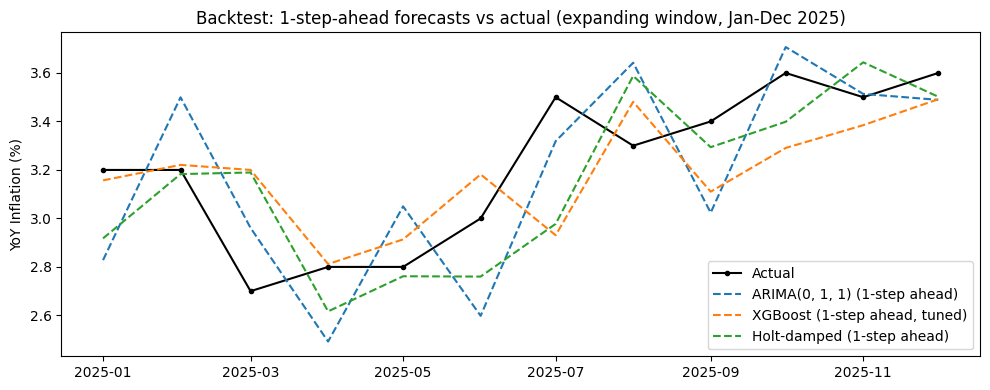

In [ ]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(dates_bt, actual_arima, label='Actual', color='black', marker='o', markersize=3)
ax.plot(dates_bt, pred_arima, label=f'ARIMA{best_order} (1-step ahead)', linestyle='--')
ax.plot(dates_bt_ml, pred_xgb, label='XGBoost (1-step ahead, tuned)', linestyle='--')
ax.plot(dates_bt_holt, pred_holt, label='Holt-damped (1-step ahead)', linestyle='--')
ax.set_title('Backtest: 1-step-ahead forecasts vs actual (expanding window, Jan-Dec 2025)')
ax.set_ylabel('YoY Inflation (%)')
ax.legend()
plt.tight_layout()
plt.show()

Interpretation of Forecast Paths

The figure compares one-step-ahead forecasts from the ARIMA(0,1,1), XGBoost, and Holt damped-trend models against the actual YoY inflation values during the January–December 2025 evaluation period.

All three models follow the general movement of the observed inflation series, indicating that they capture the overall persistence and gradual changes in inflation dynamics. However, differences are visible in how each model responds to month-to-month fluctuations.

The ARIMA(0,1,1) model captures the broad direction of the series but shows some larger deviations during periods of rapid movement. For example, it underestimates inflation in July 2025 and overestimates inflation in August 2025. This behaviour is consistent with the characteristics of a simple ARIMA model, where forecasts tend to be influenced mainly by historical patterns and recent forecast errors.

The XGBoost model generally tracks the actual inflation values more closely throughout the test period. It responds relatively well to increases and decreases in inflation, particularly around the upward movement observed between June and August 2025. This aligns with its lower MAE and MAPE values, suggesting that the additional lag-based and rolling statistical features provided useful predictive information.

The Holt damped-trend model provides a smoother forecast path and captures the overall upward movement toward the end of the evaluation period. Its forecasts avoid excessive fluctuations by gradually reducing the influence of recent trends over the forecast horizon. This behaviour contributes to its competitive RMSE performance, as the model limits large forecast deviations.

Overall, the figure demonstrates that the models provide different forecasting behaviours:

ARIMA provides a statistically driven benchmark based on historical dependence.
XGBoost adapts more flexibly to short-term changes through engineered features.
Holt damped trend provides a smoother trend-based forecast.

The visual comparison supports the numerical evaluation results, where XGBoost achieved the lowest MAE and MAPE, while Holt achieved a slightly lower RMSE.

## 8. Final refit and 2026 forecast

All three models (ARIMA, XGBoost, Holt-damped-trend) are refit on the **full** Jan 2020 – Dec 2025
training sample (all 72 observations, no held-out data) and used to forecast **January 2026 –
December 2026** (12 months ahead), with 95% prediction intervals. The model with the lowest
backtest MAE from Section 6 is selected automatically as the **primary** forecast (the one used
for the exported point forecast and interval); the other two are kept in the output table for
comparison.

In [ ]:

plt.rcParams['figure.figsize'] = (10,4)

# Final refit: all three models refit on the FULL 72-month training sample (Jan 2020-Dec 2025).
forecast_dates = pd.date_range('2026-01-01', periods=12, freq='MS')

# ARIMA final forecast
final_arima_model = ARIMA(ts, order=best_order).fit()
arima_fc = final_arima_model.get_forecast(steps=12)
arima_point = arima_fc.predicted_mean.values
arima_ci = arima_fc.conf_int(alpha=0.05)
arima_lower, arima_upper = arima_ci.iloc[:,0].values, arima_ci.iloc[:,1].values

# XGBoost final forecast (recursive: predict one month, feed it back in as a lag, repeat)
final_xgb_model = XGBRegressor(random_state=42, **best_params)
final_xgb_model.fit(feat_df[feature_cols], feat_df['y'])

history = ts.copy()
xgb_point = []
for date in forecast_dates:
    row = {}
    for lag in [1,2,3,6,12]:
        row[f'lag{lag}'] = history.iloc[-lag]
    row['roll_mean3'] = history.iloc[-3:].mean()
    row['roll_std3']  = history.iloc[-3:].std()
    row['month'] = date.month
    x_row = pd.DataFrame([row])[feature_cols]
    pred = final_xgb_model.predict(x_row)[0]
    xgb_point.append(pred)
    history.loc[date] = pred
xgb_point = np.array(xgb_point)

# --- Holt damped-trend final forecast ---
final_holt_model = ExponentialSmoothing(ts, trend='add', damped_trend=True, seasonal=None).fit(optimized=True)
holt_point = final_holt_model.forecast(12).values
holt_resid_std = np.std(actual_holt - pred_holt, ddof=1)

h = np.arange(1, 13)  # horizon 1..12

# Residual-based 95% interval: XGBoost has no native prediction interval, so we use the
# spread of the backtest residuals (actual - predicted) as a stand-in. This assumes the
# 1-step-ahead error distribution holds at longer horizons, which understates uncertainty
# further out -- noted in Section 8's limitations.
xgb_resid_std = np.std(actual_xgb - pred_xgb, ddof=1)
#xgb_lower = xgb_point - 1.96*xgb_resid_std
#xgb_upper = xgb_point + 1.96*xgb_resid_std

xgb_lower = xgb_point - 1.96 * xgb_resid_std * np.sqrt(h)
xgb_upper = xgb_point + 1.96 * xgb_resid_std * np.sqrt(h)

holt_lower = holt_point - 1.96 * holt_resid_std * np.sqrt(h)
holt_upper = holt_point + 1.96 * holt_resid_std * np.sqrt(h)

# --- Pick the primary model by lowest backtest MAE (from Section 6) ---
mae_by_model = {'ARIMA': mae_a, 'XGBoost': mae_x, 'Holt-damped': mae_h}
primary_model = min(mae_by_model, key=mae_by_model.get)
print("Primary model selected by lowest backtest MAE:", primary_model, mae_by_model)

primary_point, primary_lower, primary_upper = {
    'ARIMA':       (arima_point, arima_lower, arima_upper),
    'XGBoost':     (xgb_point,   xgb_lower,   xgb_upper),
    'Holt-damped': (holt_point,  holt_lower,  holt_upper),
}[primary_model]

forecast_df = pd.DataFrame({
    'Month': forecast_dates.strftime('%Y-%m'),
    'ARIMA_Forecast': arima_point.round(2),
    'XGBoost_Forecast': xgb_point.round(2),
    'Holt_Forecast': holt_point.round(2),
    'Primary_Model': primary_model,
    'Point_Forecast': primary_point.round(2),
    'Lower_95': primary_lower.round(2),
    'Upper_95': primary_upper.round(2),
})
forecast_df

Primary model selected by lowest backtest MAE: XGBoost {'ARIMA': np.float64(0.2519526468611814), 'XGBoost': np.float64(0.20364348093668624), 'Holt-damped': np.float64(0.2175243154877519)}


,Month,ARIMA_Forecast,XGBoost_Forecast,Holt_Forecast,Primary_Model,Point_Forecast,Lower_95,Upper_95
0,2026-01,3.69,3.52,3.61,XGBoost,3.52,2.98,4.06
1,2026-02,3.69,3.53,3.61,XGBoost,3.53,2.77,4.30
2,2026-03,3.69,3.59,3.62,XGBoost,3.59,2.65,4.53
3,2026-04,3.69,3.59,3.62,XGBoost,3.59,2.50,4.68
4,2026-05,3.69,3.59,3.62,XGBoost,3.59,2.38,4.81
5,2026-06,3.69,3.57,3.63,XGBoost,3.57,2.24,4.90
6,2026-07,3.69,3.47,3.63,XGBoost,3.47,2.03,4.90
7,2026-08,3.69,3.47,3.63,XGBoost,3.47,1.94,5.01
8,2026-09,3.69,3.47,3.63,XGBoost,3.47,1.84,5.10
9,2026-10,3.69,3.47,3.64,XGBoost,3.47,1.75,5.19


XGBoost was selected as the primary forecasting model because it achieved the lowest MAE during the out-of-sample backtest.

Since XGBoost does not provide analytical prediction intervals, uncertainty bounds were estimated using the standard deviation of historical backtest residuals. The uncertainty was allowed to increase with the forecast horizon using a square-root-of-time scaling assumption. This provides an approximate interval rather than a formal statistical confidence interval.

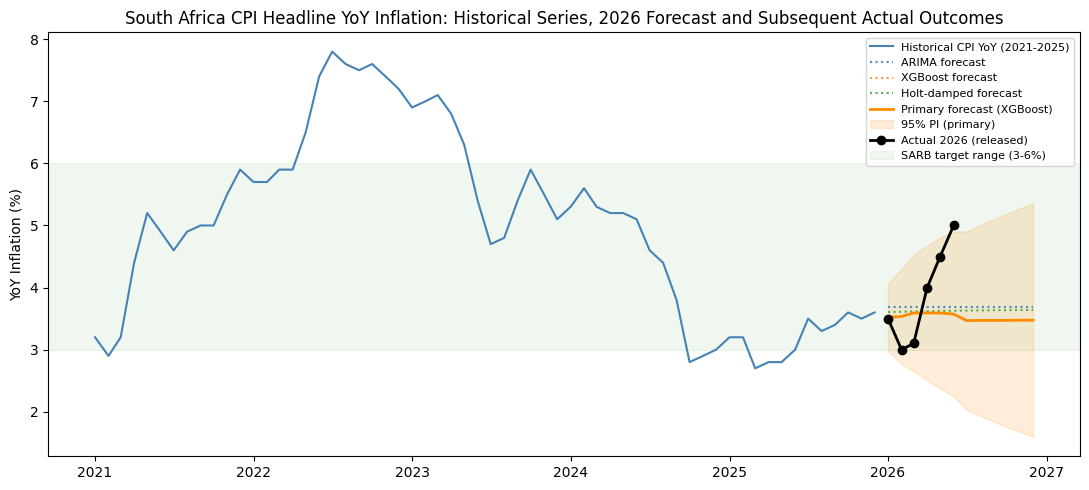

Saved: CPI_2026_Forecast.xlsx


In [ ]:
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(ts.index, ts.values, label='Historical CPI YoY (2021-2025)', color='steelblue')
ax.plot(forecast_dates, arima_point, label='ARIMA forecast', linestyle=':', alpha=0.8)
ax.plot(forecast_dates, xgb_point, label='XGBoost forecast', linestyle=':', alpha=0.8)
ax.plot(forecast_dates, holt_point, label='Holt-damped forecast', linestyle=':', alpha=0.8)
ax.plot(forecast_dates, primary_point, label=f'Primary forecast ({primary_model})', color='darkorange', linewidth=2)
ax.fill_between(forecast_dates, primary_lower, primary_upper, color='darkorange', alpha=0.15, label='95% PI (primary)')

# Overlay the actual released 2026 values (Jan-Jun) for a direct visual check
actual_2026 = ts_full.loc['2026-01-01':'2026-06-01'].dropna()
ax.plot(actual_2026.index, actual_2026.values, label='Actual 2026 (released)', color='black', marker='o', linewidth=2)

ax.axhspan(3, 6, color='green', alpha=0.06, label='SARB target range (3-6%)')
ax.set_title('South Africa CPI Headline YoY Inflation: Historical Series, 2026 Forecast and Subsequent Actual Outcomes')
ax.set_ylabel('YoY Inflation (%)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

forecast_df.to_excel('CPI_2026_Forecast.xlsx', index=False)
print("Saved: CPI_2026_Forecast.xlsx")

Interpretation of Final Inflation Forecast

The figure presents South Africa’s historical headline YoY CPI inflation from 2021 to 2025 together with the 12-month ahead forecasts for 2026 generated by the ARIMA(0,1,1), XGBoost, and Holt damped-trend models. The shaded region represents the approximate 95% prediction interval around the primary forecast.

The historical series shows the inflation shock experienced during 2022, when CPI inflation increased sharply and exceeded the upper bound of the SARB’s 3–6% target range. Inflation subsequently declined through 2023 and 2024, returning to within the target range and moving toward the lower end of the band during 2025.

The three forecasting models produce relatively similar inflation paths for 2026, with forecasts remaining around 3.5%–3.7% throughout the forecast horizon. The ARIMA model produces a relatively constant forecast path of approximately 3.69%, reflecting the tendency of a differenced ARIMA model to converge toward a stable level. The Holt damped-trend model produces slightly higher values around 3.6%, reflecting recent trend information while gradually reducing the influence of the trend. The XGBoost model, selected as the primary model based on the lowest backtest MAE, forecasts inflation slightly lower at approximately 3.5%.

The forecast path suggests that inflation is expected to remain within the SARB’s target range during 2026 under the central forecast scenario. However, the widening prediction interval highlights increasing uncertainty as the forecast horizon extends. The interval indicates that although the central forecast remains close to the lower half of the target range, alternative outcomes are possible depending on future economic conditions.

The released 2026 actual observations shown on the plot move above the model forecasts, reaching approximately 5% by the latest available observation. This indicates that the realised inflation path was higher than the original forecast trajectory. The deviation highlights the challenge of forecasting inflation, where unexpected changes in economic conditions can cause actual outcomes to differ from model-based projections.

## 9.Interpretation, Uncertainty and Limitations

**Interpretation of the Forecasts**

Interpretation of the Forecasts

The 12-month ahead forecasts generated by the three models show similar expected inflation paths for 2026. The ARIMA(0,1,1) model produces a relatively stable forecast of approximately 3.7%, while the Holt damped-trend model forecasts inflation at around 3.6%. The XGBoost model, which was selected as the primary forecasting model, produces forecasts of approximately 3.5% throughout the forecast horizon. All three models remain within the South African Reserve Bank’s 3–6% inflation target range, suggesting that the models expect inflation to remain within the target range under the central forecast scenario.

The forecast paths also highlight differences in model behaviour. The ARIMA(0,1,1) forecasts gradually converge toward a stable level as the forecast horizon increases. This is consistent with the characteristics of low-order ARIMA models, where future predictions are strongly influenced by historical patterns and recent forecast errors. Similarly, the recursive XGBoost forecasts become smoother over longer horizons because future predictions increasingly depend on previously generated forecasts rather than newly observed inflation values. These patterns represent the mathematical behaviour of the models and should not be interpreted as a conclusion that inflation will remain constant in the future.

The Holt damped-trend model provides a more trend-based forecast path by incorporating recent movements in the inflation series while gradually reducing the influence of the trend through damping. This allows the model to capture recent changes while avoiding excessive long-term trend continuation.

Based on the out-of-sample backtesting results, XGBoost was selected as the primary forecasting model because it achieved the lowest Mean Absolute Error (MAE = 0.204). This indicates that XGBoost produced the smallest average forecast errors during the evaluation period. Although the Holt damped-trend model achieved a slightly lower RMSE, XGBoost provided the strongest overall performance according to the selected evaluation criterion.

Out-of-Sample Forecast Check
Although the 2026 observations were not used during model training, actual Stats SA inflation releases for January–June 2026 were available for comparison. The observed inflation values increased from approximately 3.5% in January 2026 to 5.0% in June 2026, showing a stronger upward movement than predicted by the forecasting models.

Compared with the first six forecast values, all three models captured the general inflation level but underestimated the acceleration that occurred during the second quarter of 2026. This highlights the challenge of forecasting inflation, particularly when future movements differ from historical patterns observed in the training data.

The difference between forecasted and realised inflation does not necessarily indicate model failure. The models were trained using information available up to December 2025 and therefore relied on historical inflation behaviour. Since headline CPI inflation already incorporates changes in consumer prices across categories such as food, fuel, electricity, and other goods and services, the models capture the overall impact of these factors once they appear in the inflation series. However, the models do not separately include additional indicators that may provide early information about future inflation movements, such as changes in specific price components, exchange rates, interest rates, or global commodity conditions.

**Limitations**
Several limitations should be considered when interpreting the forecasting results.

Firstly, the dataset contains 72 monthly observations, which is a relatively short historical period for modelling inflation behaviour. Although the sample captures important events, including the significant inflation increase during 2022, it contains limited examples of rare and extreme inflation movements. As a result, uncertainty estimates may not fully represent the potential impact of future economic shocks.

Secondly, the forecasting models rely primarily on the historical behaviour of the YoY CPI inflation series. The target variable itself reflects changes in consumer prices across the economy; therefore, the models capture the overall effect of factors such as fuel, food, and electricity price movements through past inflation observations. However, the models do not separately model the individual economic drivers behind these movements. This may limit their ability to anticipate sudden changes before those effects are reflected in the historical inflation data.

Thirdly, the different forecasting behaviours observed across the models are related to their underlying structures. ARIMA and recursive XGBoost forecasts may become flatter over longer horizons because they rely heavily on previous observations and generated predictions. While this improves forecast stability, it may reduce responsiveness when inflation experiences unexpected changes. The Holt damped-trend model provides an alternative by incorporating recent trends while gradually reducing their influence over time.

The uncertainty intervals should also be interpreted carefully. Since XGBoost does not produce analytical prediction intervals, the uncertainty bounds were estimated using historical backtest residuals and a horizon-scaling approach. Therefore, these intervals provide an approximate indication of forecast uncertainty rather than formal statistical confidence intervals. If the lower bound becomes negative, this should be interpreted as a limitation of the symmetric interval calculation rather than a direct prediction of deflation.

Finally, forecasting models should be updated as additional inflation observations become available. A forecast generated using information available at the end of 2025 will naturally become less accurate as future economic conditions change. Re-estimating the models with new observations would allow them to incorporate recent inflation dynamics and improve future forecasting performance.